In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import pyarrow as pa
import pyarrow.dataset as ds
import pyarrow.compute as pc
from pathlib import Path
from scipy.spatial import cKDTree
import seaborn as sns
from utils import construct_path, read_feather_gcs, pq_to_xy
from utils import DATA, RESULTS
pd.set_option('display.max_rows', 300)

In [2]:
DATA

PosixPath('/home/guardomayas/NUIN/sjbcs/male_cns_var/connectome_data')

In [4]:
data_dir = (Path(DATA/"processed"))
col_nodes = pd.read_feather(data_dir / "columnar_nodes.feather")
T4_T5_nodes = pd.read_feather(data_dir / "T4_T5_home_columns.feather")
ct1_edgelist = pd.read_feather(data_dir / "ct1_edgelist_full.feather")


In [5]:
nodes_df = pd.concat([col_nodes, T4_T5_nodes], ignore_index=True).drop_duplicates("malecns_09_id", keep="last").copy()
nodes_df

,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,100043,right,C2,gaba,0.528316,24.0,17.0,6.0,-2.0
1,100062,right,C2,unclear,0.398571,24.0,35.0,6.0,16.0
2,100134,right,C2,unclear,0.405942,22.0,31.0,4.0,12.0
3,100156,right,C2,unclear,0.467389,28.0,38.0,10.0,19.0
4,100229,right,C2,unclear,0.581083,27.0,13.0,9.0,-6.0
...,...,...,...,...,...,...,...,...,...
30298,139284,right,T5d,unclear,0.974427,7.0,2.0,-11.0,-17.0
30299,163871,right,T5d,unclear,0.974427,31.0,39.0,13.0,20.0
30300,142354,right,T5d,unclear,0.974427,34.0,21.0,16.0,2.0
30301,160570,right,T5d,unclear,0.974427,27.0,39.0,9.0,20.0


## Add offset to ct1_edges and filter out noncolumnar

In [6]:
post_home = nodes_df[
    [
        "malecns_09_id",
        "hex_1",
        "hex_2",
        "p",
        "q",
    ]
].rename(columns={
    "malecns_09_id": "post",
    "hex_1": "post_hex_1",
    "hex_2": "post_hex_2",
    "p": "post_p",
    "q": "post_q",
})

ct1_edges_annot = ct1_edgelist.merge(
    post_home,
    on="post",
    how="left"
)

pre_home = nodes_df[
    [
        "malecns_09_id",
        "hex_1",
        "hex_2",
        "p",
        "q",
    ]
].rename(columns={
    "malecns_09_id": "pre",
    "hex_1": "pre_hex_1",
    "hex_2": "pre_hex_2",
    "p": "pre_p",
    "q": "pre_q",
})

ct1_edges_annot = ct1_edges_annot.merge(
    pre_home,
    on="pre",
    how="left"
)

In [7]:
ct1_edges_annot = ct1_edges_annot.query("count > 3").copy().reset_index(drop=True)
ct1_edges_annot["dp_syn_to_post"] = (
    ct1_edges_annot["syn_p"] - ct1_edges_annot["post_p"]
)

ct1_edges_annot["dq_syn_to_post"] = (
    ct1_edges_annot["syn_q"] - ct1_edges_annot["post_q"]
)

ct1_edges_annot["dp_syn_to_pre"] = (
    ct1_edges_annot["syn_p"] - ct1_edges_annot["pre_p"]
)

ct1_edges_annot["dq_syn_to_pre"] = (
    ct1_edges_annot["syn_q"] - ct1_edges_annot["pre_q"]
)

ct1_edges_annot["ct1_direction"] = np.select(
    [
        ct1_edges_annot["pre_cell_type"].eq("CT1"),
        ct1_edges_annot["post_cell_type"].eq("CT1"),
    ],
    [
        "CT1_output",
        "CT1_input",
    ],
    default="not_CT1",
)


In [8]:
ct1_final_edges = ct1_edges_annot.copy()

is_output = ct1_final_edges["ct1_direction"].eq("CT1_output")
is_input  = ct1_final_edges["ct1_direction"].eq("CT1_input")

# Source location
ct1_final_edges["source_hex_1"] = np.where(
    is_output,
    ct1_final_edges["syn_hex_1"],
    ct1_final_edges["pre_hex_1"],
)

ct1_final_edges["source_hex_2"] = np.where(
    is_output,
    ct1_final_edges["syn_hex_2"],
    ct1_final_edges["pre_hex_2"],
)

ct1_final_edges["source_p"] = np.where(
    is_output,
    ct1_final_edges["syn_p"],
    ct1_final_edges["pre_p"],
)

ct1_final_edges["source_q"] = np.where(
    is_output,
    ct1_final_edges["syn_q"],
    ct1_final_edges["pre_q"],
)

# Target/reference location
ct1_final_edges["target_hex_1"] = np.where(
    is_output,
    ct1_final_edges["post_hex_1"],
    ct1_final_edges["syn_hex_1"],
)

ct1_final_edges["target_hex_2"] = np.where(
    is_output,
    ct1_final_edges["post_hex_2"],
    ct1_final_edges["syn_hex_2"],
)

ct1_final_edges["target_p"] = np.where(
    is_output,
    ct1_final_edges["post_p"],
    ct1_final_edges["syn_p"],
)

ct1_final_edges["target_q"] = np.where(
    is_output,
    ct1_final_edges["post_q"],
    ct1_final_edges["syn_q"],
)

ct1_final_edges["dp"] = (
    ct1_final_edges["target_p"] - ct1_final_edges["source_p"]
)

ct1_final_edges["dq"] = (
    ct1_final_edges["target_q"] - ct1_final_edges["source_q"]
)

final_cols = [
    "pre",
    "post",
    "pre_cell_type",
    "post_cell_type",
    "ct1_direction",
    "count",
    "neuropil",

    "source_hex_1",
    "source_hex_2",
    "source_p",
    "source_q",

    "target_hex_1",
    "target_hex_2",
    "target_p",
    "target_q",

    "dp",
    "dq",

    # # "syn_column_id",
    # "syn_hex_1",
    # "syn_hex_2",
    # "syn_p",
    # "syn_q",
    "syn_top_nt",
    "mean_syn_top_p",
]

ct1_final_edges = ct1_final_edges[final_cols].rename(columns={
    "syn_top_nt": "edge_nt",
    "mean_syn_top_p": "edge_nt_score",
})

ct1_final_edges["count"].min() #Not an effect of thresholding, 
                            # but just including only columnar and T4/T5 nodes

np.int64(4)

In [9]:
ct1_final_edges.to_feather(data_dir / "ct1_columnar_edges.feather", compression="uncompressed")

In [10]:
ct1_inputs = ct1_final_edges.query("ct1_direction == 'CT1_input'").copy()
ct1_outputs = ct1_final_edges.query("ct1_direction == 'CT1_output'").copy()


In [11]:
ct1_inputs

,pre,post,pre_cell_type,post_cell_type,ct1_direction,count,neuropil,source_hex_1,source_hex_2,source_p,source_q,target_hex_1,target_hex_2,target_p,target_q,dp,dq,edge_nt,edge_nt_score
12541,12140,10009,MeVPLo1,CT1,CT1_input,4,LO,NaN,NaN,NaN,NaN,30.0,35.0,12.0,16.0,NaN,NaN,glutamate,0.917674
12542,17871,10009,Mi1,CT1,CT1_input,5,ME,29.0,18.0,11.0,-1.0,29.0,18.0,11.0,-1.0,0.0,0.0,acetylcholine,0.998732
12543,21348,10009,Mi9,CT1,CT1_input,5,ME,26.0,17.0,8.0,-2.0,26.0,17.0,8.0,-2.0,0.0,0.0,acetylcholine,0.699391
12544,23606,10009,Mi1,CT1,CT1_input,4,ME,25.0,13.0,7.0,-6.0,25.0,13.0,7.0,-6.0,0.0,0.0,acetylcholine,0.999755
12545,24579,10009,Tm1,CT1,CT1_input,6,LO,17.0,25.0,-1.0,6.0,17.0,25.0,-1.0,6.0,0.0,0.0,acetylcholine,0.999503
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17855,554311,10009,T4d,CT1,CT1_input,4,ME,25.0,10.0,7.0,-9.0,25.0,10.0,7.0,-9.0,0.0,0.0,acetylcholine,0.995642
17856,554447,10009,Tm9,CT1,CT1_input,25,LO,3.0,7.0,-15.0,-12.0,3.0,7.0,-15.0,-12.0,0.0,0.0,acetylcholine,0.996686
17857,554753,10009,T4b,CT1,CT1_input,4,ME,10.0,27.0,-8.0,8.0,10.0,27.0,-8.0,8.0,0.0,0.0,acetylcholine,0.997756
17858,579914,10009,Tm9,CT1,CT1_input,6,LO,7.0,6.0,-11.0,-13.0,7.0,5.0,-11.0,-14.0,0.0,-1.0,acetylcholine,0.998023


In [12]:

ct1_input_coverage = (
    ct1_inputs
    .groupby(["target_hex_1", "target_hex_2", "target_p", "target_q"], as_index=False)
    .agg(
        n_edges=("count", "size"),
        n_synapses=("count", "sum"),
        n_pre_cells=("pre", "nunique"),
        n_post_cells=("post", "nunique"),
        n_partner_types=("post_cell_type", "nunique"),
    )
    .rename(columns={
        "target_p": "p",
        "target_q": "q",})
    )

ct1_input_coverage

,target_hex_1,target_hex_2,p,q,n_edges,n_synapses,n_pre_cells,n_post_cells,n_partner_types
0,1.0,7.0,-17.0,-12.0,1,10,1,1,1
1,2.0,6.0,-16.0,-13.0,2,14,2,1,1
2,2.0,7.0,-16.0,-12.0,2,20,2,1,1
3,2.0,8.0,-16.0,-11.0,7,56,7,1,1
4,2.0,9.0,-16.0,-10.0,6,40,6,1,1
...,...,...,...,...,...,...,...,...,...
866,36.0,31.0,18.0,12.0,2,21,2,1,1
867,36.0,32.0,18.0,13.0,1,5,1,1,1
868,36.0,33.0,18.0,14.0,3,30,3,1,1
869,36.0,34.0,18.0,15.0,2,17,2,1,1


## Plot

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
import matplotlib as mpl

def plot_hexeye_value(
    column_summary,
    value_col="n_types_present",
    hexsize=1.0,
    rotate=-np.pi/6,
    cmap="viridis",
    vmin=None,
    vmax=None,
    title="T4/T5 subtype coverage per column",
    label_cols=False,
    ax=None,
):
    df = column_summary.copy()

    df = df.dropna(subset=["p", "q", value_col]).copy()

    x, y = pq_to_xy(
        df["p"].to_numpy(),
        df["q"].to_numpy(),
        hexsize=hexsize,
        rotate=rotate,
    )

    df["x_plot"] = x
    df["y_plot"] = y

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    else:
        fig = ax.figure

    patches = []
    values = []

    for _, row in df.iterrows():
        patches.append(
            RegularPolygon(
                (row["x_plot"], row["y_plot"]),
                numVertices=6,
                radius=hexsize * 0.95,
                orientation=np.pi / 6,
            )
        )
        values.append(row[value_col])

    norm = Normalize(vmin=vmin, vmax=vmax)

    collection = PatchCollection(
        patches,
        cmap=cmap,
        norm=norm,
        edgecolor="k",
        linewidth=0.25,
    )
    collection.set_array(np.asarray(values))
    ax.add_collection(collection)

    if label_cols:
        for _, row in df.iterrows():
            if row["missing_types"] == "":
                continue
            ax.text(
                row["x_plot"],
                row["y_plot"],
                row["missing_types"],
                ha="center",
                va="center",
                fontsize=6,
                color="k",
                rotation=0,
            )
            
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.axis("off")
    ax.set_title(title)

    if vmax is None:
        vmax = df[value_col].max()
        vmin = df[value_col].min()
    
    cbar = fig.colorbar(
        collection,
        ax=ax,
        shrink=0.75,
        pad=0.02,
    )
    cbar.set_label(value_col)
    cbar.set_ticks(np.arange(vmin, vmax + 1,10))

    return fig, ax

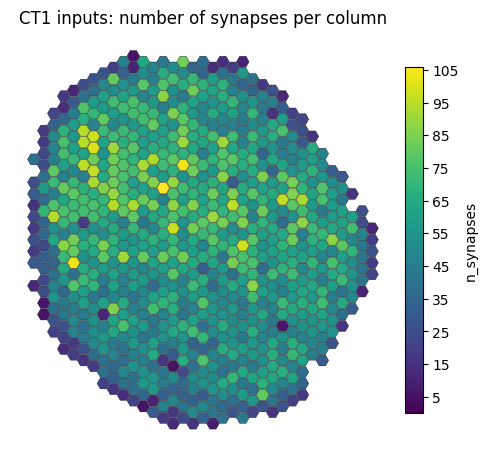

In [14]:
fig, ax =  plot_hexeye_value(
    ct1_input_coverage,
    value_col="n_synapses",
    hexsize=1.0,
    rotate=-np.pi/6,
    cmap="viridis",
    vmin=0,
    # vmax=8,
    title="CT1 inputs: number of synapses per column",
    label_cols=False,
    ax=None,)